# Oversampling

### <i> Using ADASYN (Adaptive Synthetic Sampling).

<i> In this notebook, you'll be shown how <strong style='color:red'> NOT to use ADASYN</strong> and how overlap can make ADASYN counter-productive </i>

<br>
<br>

In [1]:
# pip install imblearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Load a new dataframe.
df = pd.read_csv("../diabetes.csv")
df

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,1,89,66,23,94,28.1,0.167,21,neg
1,0,137,40,35,168,43.1,2.288,33,pos
2,3,78,50,32,88,31.0,0.248,26,pos
3,2,197,70,45,543,30.5,0.158,53,pos
4,1,189,60,23,846,30.1,0.398,59,pos
...,...,...,...,...,...,...,...,...,...
387,0,181,88,44,510,43.3,0.222,26,pos
388,1,128,88,39,110,36.5,1.057,37,pos
389,2,88,58,26,16,28.4,0.766,22,neg
390,10,101,76,48,180,32.9,0.171,63,neg


---

### Testing ADASYN

In [2]:
from imblearn.over_sampling import ADASYN

# X, y split
y = df["diabetes"]
X = df.drop("diabetes", axis=1)

# Load adasyn
adasyn = ADASYN(random_state=42)

# Resample X and Y separately
X_oversampled, y_oversampled = adasyn.fit_resample(X, y)

df_oversampled = pd.DataFrame(X_oversampled)
df_oversampled["diabetes"] = y_oversampled


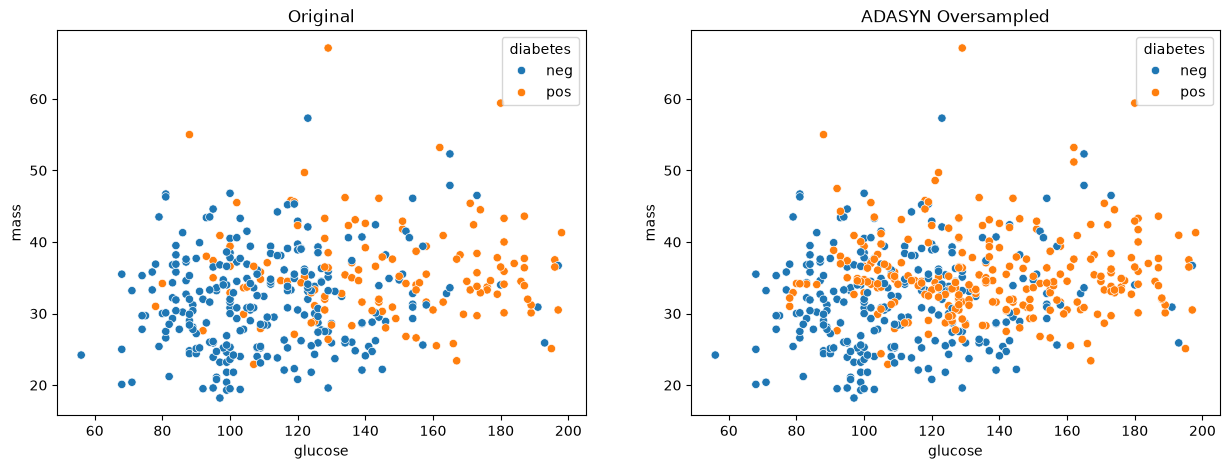

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(df, x="glucose", y="mass", hue="diabetes", ax=axes[0])
sns.scatterplot(df_oversampled, x="glucose", y="mass", hue="diabetes", ax=axes[1])

axes[0].set_title(f"Original")
axes[1].set_title(f"ADASYN Oversampled")
plt.show()


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>What changed?</h3>


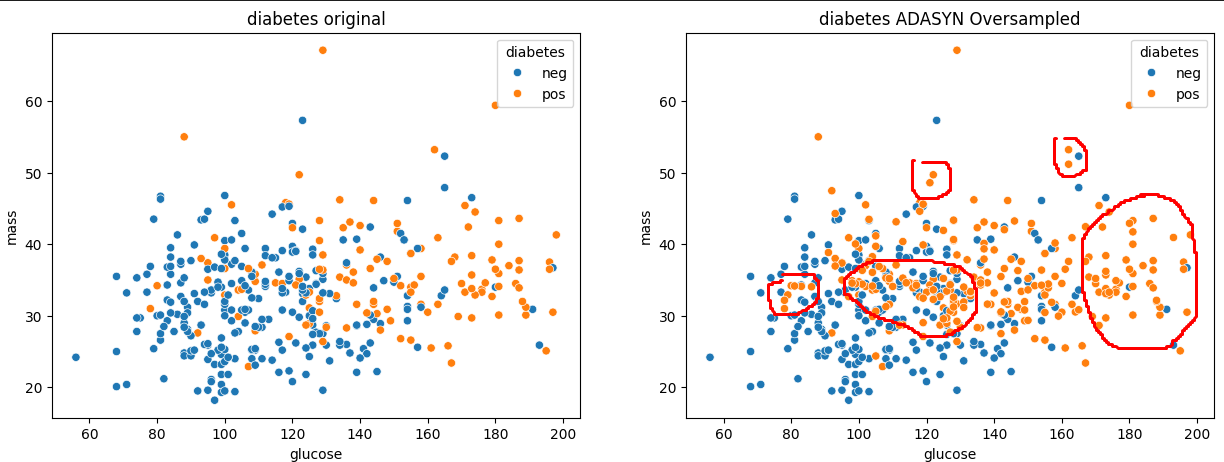

<i> We have introduced stronger relationships for our minority clusters/groups. BUT in turn, 
<strong style='color:orange ; background-color:black;'> we have made our overlap much, much worse.</strong>

Therefore, <strong style='color:orange ; background-color:black;'> when overlap exists in your dataset, DO NOT USE ADASYN. It will tank performance. </strong>

</div>